# DART in LightGBM

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train LightGBM with DART to predict the rent price of an apartment. We train a model with the default parameters and early stopping, train DART with the same number of trees, and then see how the drop rate and the skip rate change it.

LightGBM ships a scikit-learn wrapper, `LGBMRegressor` and `LGBMClassifier`, which fits into scikit-learn pipelines and searches. In this course we use the native API, `lgb.train` with a `Dataset`, because it exposes the full feature set of the library.

In [1]:
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [3]:
# LightGBM splits on categories directly, so we keep them as pandas categories instead of integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].astype("category")

# LightGBM takes missing values, so we leave NaN as it is

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [5]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Prepare the data for LightGBM

LightGBM trains on a `Dataset`, which holds the data already cut into bins. The test set takes the train set as `reference`, so that both use the same bins.

In [6]:
train_set = lgb.Dataset(X_train, y_train)
test_set = lgb.Dataset(X_test, y_test, reference=train_set)

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [7]:
params = {
    # learning task
    "objective": "regression",   # squared error
    "metric": "rmse",

    # sampling
    "data_sample_strategy": "bagging",
    "bagging_fraction": 1.0,     # share of the rows for each tree
    "bagging_freq": 0,           # 0 means no bagging
    "feature_fraction": 1.0,     # share of the features for each tree

    # feature processing
    "enable_bundle": True,       # bundles features that are never nonzero together; the trees stay the same
    "max_bin": 255,              # maximum number of bins per feature

    # tree structure and algorithm
    "boosting": "gbdt",
    "learning_rate": 0.1,
    "early_stopping_round": 50,  # the early-stopping rule, the default 0 means no early stopping
    "num_leaves": 31,            # the main limit of a leaf-wise tree
    "max_depth": -1,             # no limit
    "min_data_in_leaf": 20,

    # dart, used only when boosting is dart
    "drop_rate": 0.1,
    "max_drop": 50,              # the most trees one round can drop
    "skip_drop": 0.5,
    "uniform_drop": False,
    "xgboost_dart_mode": False,

    # regularization
    "min_gain_to_split": 0.0,
    "lambda_l2": 0.0,
    "lambda_l1": 0.0,

    # categorical features
    "max_cat_to_onehot": 4,      # up to this many categories, one category against the rest
    "max_cat_threshold": 32,
    "min_data_per_group": 100,

    # additional important parameters
    "device_type": "cpu",
    "seed": 0,
    "num_threads": 4,            # fixed, so that the training times are comparable
    "verbose": -1,               # keep the warnings out of the output
}

We let the model grow up to 2000 trees and stop when the rmse in the test set has not improved for 50 rounds. We set this rule with `early_stopping_round` in the parameters, and `lgb.train` adds the early-stopping callback by itself. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
evals_result = {}

booster = lgb.train(
    params,
    train_set,
    num_boost_round=2000,
    valid_sets=[train_set, test_set],
    valid_names=["train", "test"],
    callbacks=[
        lgb.record_evaluation(evals_result),
        lgb.log_evaluation(period=100),
    ],
)

booster.best_iteration, booster.num_trees()

[100]	train's rmse: 391.148	test's rmse: 436.334


[200]	train's rmse: 351.382	test's rmse: 423.951


[300]	train's rmse: 326.106	test's rmse: 419.861


[400]	train's rmse: 309.228	test's rmse: 416.619


[500]	train's rmse: 292.797	test's rmse: 415.074


(533, 533)

The test rmse reached its lowest value at round 533, and early stopping trained 50 more rounds before it gave up. `lgb.train` drops those extra rounds and returns a booster with 533 trees, because with the default `keep_training_booster=False` it rebuilds the booster from a copy that stops at the best round.

In [9]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        rmse = root_mean_squared_error(y, model.predict(X))
        r2 = r2_score(y, model.predict(X))
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(booster, X_train, y_train, X_test, y_test)

train rmse: 288.15, r2: 0.9014


test rmse: 414.53, r2: 0.7727


The model fits the train set better than the test set, with an rmse of 288 against 415.

### Train the model with DART

We saw in the lecture on DART hyperparameters that in LightGBM, setting `boosting` to dart is enough to turn DART on, because `drop_rate` is already 0.1 by default. We keep all the dropout parameters at their defaults.

LightGBM does not allow early stopping in DART mode, because every round drops a random set of trees. So we remove `early_stopping_round` from the parameters and train DART for the same 533 trees as the default model. We train the default model again next to it, record the rmse in the test set after every tree, and measure the training time. The times depend on the machine, so we should read them relative to each other.

In [10]:
num_rounds = booster.best_iteration
params.pop("early_stopping_round")

dart_params = {**params, "boosting": "dart"}

num_rounds

533

In [11]:
def scores(model, X_train, y_train, X_test, y_test):
    predictions = model.predict(X_test)
    return {
        "train rmse": root_mean_squared_error(y_train, model.predict(X_train)),
        "test rmse": root_mean_squared_error(y_test, predictions),
        "test r2": r2_score(y_test, predictions),
    }

In [12]:
results = {}
curves = {}
for name, setting in {"gbdt": params, "dart": dart_params}.items():
    evals_result = {}
    start = time.perf_counter()
    model = lgb.train(
        setting,
        train_set,
        num_boost_round=num_rounds,
        valid_sets=[test_set],
        valid_names=["test"],
        callbacks=[lgb.record_evaluation(evals_result)],
    )
    seconds = time.perf_counter() - start
    results[name] = {"seconds": seconds, **scores(model, X_train, y_train, X_test, y_test)}
    curves[name] = evals_result["test"]["rmse"]

dart_results = pd.DataFrame(results).T
dart_results.round(4)

,seconds,train rmse,test rmse,test r2
gbdt,3.0164,288.1534,414.5300,0.7727
dart,27.8503,380.8722,428.1856,0.7575


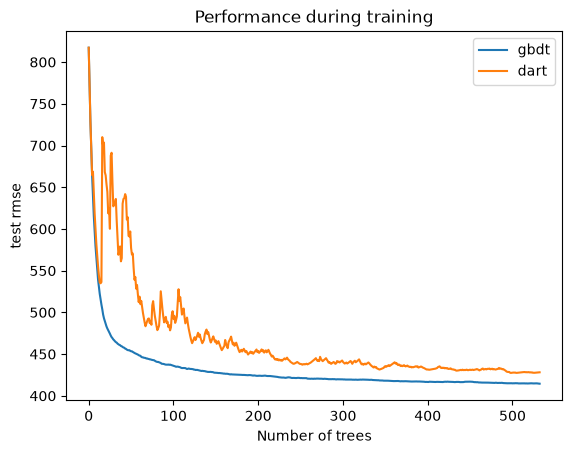

In [13]:
plt.plot(curves["gbdt"], label="gbdt")
plt.plot(curves["dart"], label="dart")
plt.xlabel("Number of trees")
plt.ylabel("test rmse")
plt.title("Performance during training")
plt.legend()
plt.show()

With the same 533 trees, DART trains much slower than the default model, and its rmse in the train set rises from 288 to 381, so dropout regularizes the model, but its rmse in the test set rises too, from 414.5 to 428.2. Its curve jumps up and down over the first 150 trees or so, as each round drops a different set of trees, and then settles a little above the curve of the default model.

Let's now change one hyperparameter at a time to understand what is going on. Every setting trains the same 533 trees, without early stopping.

In [14]:
def sweep(base_params, param, values):
    results = {}
    for value in values:
        start = time.perf_counter()
        model = lgb.train({**base_params, param: value}, train_set, num_boost_round=num_rounds)
        seconds = time.perf_counter() - start
        results[value] = {"seconds": seconds, **scores(model, X_train, y_train, X_test, y_test)}
    return pd.DataFrame(results).T

In [15]:
def plot_sweep(results, param):
    # the values are not evenly spaced, so we place them at equal distances
    positions = range(len(results))
    plt.plot(positions, results["train rmse"], marker="o", label="train rmse")
    plt.plot(positions, results["test rmse"], marker="o", label="test rmse")
    plt.axhline(dart_results.loc["gbdt", "test rmse"], color="grey", linestyle="dashed", label="gbdt test rmse")
    plt.xticks(positions, results.index)
    plt.xlabel(param)
    plt.ylabel("rmse")
    plt.title(f"Effect of {param}")
    plt.legend()
    plt.show()

### Drop rate

We saw in the lecture on DART hyperparameters that `drop_rate` sets how many trees are dropped in each round, and that a higher value regularizes more strongly. At 0, no tree is dropped, and the model is the classic gradient boosting of the default model.

With 533 trees, a `drop_rate` above 0.1 would often ask for more trees than `max_drop` lets one round drop, 50 by default. So we remove this limit with `max_drop=-1`, and `drop_rate` alone sets how many trees are dropped.

In [16]:
drop_rate_results = sweep({**dart_params, "max_drop": -1}, "drop_rate", [0, 0.05, 0.1, 0.2, 0.5])

drop_rate_results.round(4)

,seconds,train rmse,test rmse,test r2
0.00,1.4734,288.1534,414.5300,0.7727
0.05,9.5653,363.8938,419.3223,0.7675
0.10,17.8314,375.2961,423.2915,0.7630
0.20,33.8918,382.0739,426.1845,0.7598
0.50,68.7125,386.3389,427.0247,0.7588


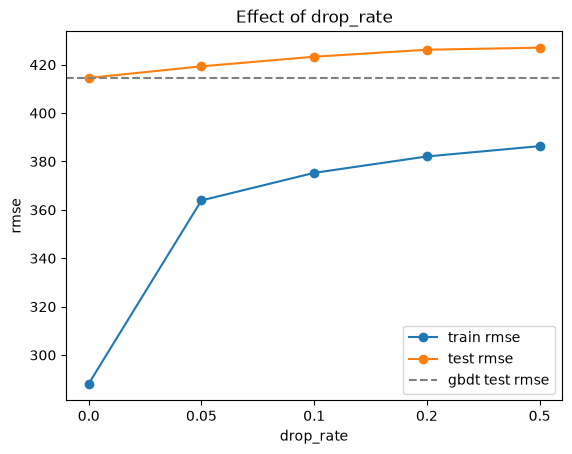

In [17]:
plot_sweep(drop_rate_results, "drop_rate")

At 0, the scores are exactly those of the default model. As `drop_rate` grows, the train rmse rises from 288 to 386 at 0.5, so dropout regularizes more strongly, and the training gets slower, because each round drops more trees. With the same 533 trees, the test rmse rises too, from 414.5 to 427.0, so on this data no drop rate does better than the default model.

### Skip drop

We saw in the lecture on DART hyperparameters that `skip_drop` is the chance that a round skips dropout completely and adds the new tree just as classic boosting does, so a higher value brings DART closer to classic boosting. Its default in LightGBM is 0.5, so about half the rounds of our DART model skip dropout.

We also saw that by default, with `xgboost_dart_mode=False`, LightGBM gives the new tree the learning rate over the sum of k and one, and each dropped tree k over the sum of k and one. With a learning rate below 1, the new tree gets back less than the dropped trees lose, so every round with dropout shrinks the predictions, while the factors of `xgboost_dart_mode=True` keep the total. So we try each `skip_drop` with both modes, keep the other dropout parameters of our DART model, and record the mean of the predictions in the train set next to the scores.

In [18]:
results = {}
for mode in [False, True]:
    for value in [0, 0.25, 0.5, 0.75]:
        start = time.perf_counter()
        model = lgb.train(
            {**dart_params, "xgboost_dart_mode": mode, "skip_drop": value},
            train_set,
            num_boost_round=num_rounds,
        )
        seconds = time.perf_counter() - start
        mean_prediction = model.predict(X_train).mean()
        results[(mode, value)] = {"seconds": seconds, "mean train prediction": mean_prediction, **scores(model, X_train, y_train, X_test, y_test)}

skip_drop_results = pd.DataFrame(results).T.rename_axis(["xgboost_dart_mode", "skip_drop"])
skip_drop_results.round(4)

seconds  mean train prediction  train rmse  \
xgboost_dart_mode skip_drop                                               
False             0.00       30.1871               815.4014    961.8763   
                  0.25       29.0320              1381.7558    491.1608   
                  0.50       17.1789              1495.1479    380.8722   
                  0.75       10.0118              1511.3849    316.7455   
True              0.00       41.4835              1527.4735    384.0548   
                  0.25       38.3126              1527.4997    365.8426   
                  0.50       29.8342              1527.5165    336.2353   
                  0.75       12.9331              1527.5163    310.3860   

                             test rmse  test r2  
xgboost_dart_mode skip_drop                      
False             0.00        930.6117  -0.1453  
                  0.25        484.2554   0.6899  
                  0.50        428.1856   0.7575  
                  0.75        410.0498   0.7776  
True              0.00        433.9423   0.7510  
                  0.25        428.4404   0.7572  
                  0.50        420.3126   0.7664  
                  0.75        416.3872   0.7707

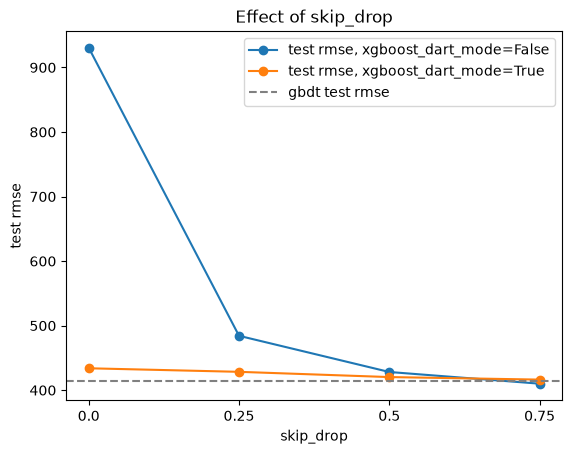

In [19]:
# the values are not evenly spaced, so we place them at equal distances
values = skip_drop_results.loc[False].index
positions = range(len(values))
for mode in [False, True]:
    plt.plot(positions, skip_drop_results.loc[mode, "test rmse"], marker="o", label=f"test rmse, xgboost_dart_mode={mode}")
plt.axhline(dart_results.loc["gbdt", "test rmse"], color="grey", linestyle="dashed", label="gbdt test rmse")
plt.xticks(positions, values)
plt.xlabel("skip_drop")
plt.ylabel("test rmse")
plt.title("Effect of skip_drop")
plt.legend()
plt.show()

With the same 533 trees, `xgboost_dart_mode=False` and a `skip_drop` of 0, the mean of the predictions in the train set is 815, far below the mean rent of 1528, so the test rmse is 930.6. As `skip_drop` grows, fewer rounds shrink the predictions: the mean rises to 1511 at 0.75, and the test rmse falls to 410.0, the lowest of the notebook.

With `xgboost_dart_mode=True`, the mean stays at 1528, and a higher `skip_drop` brings DART closer to classic boosting: the train rmse falls from 384 to 310 and the test rmse from 433.9 to 416.4, close to the 414.5 of the default model. So on this data, only a `skip_drop` of 0.75 with the default factors does better than the default model.